# Laboratório - Inteligência Artificial
## Regressão Linear (Mínimos Quadrados) e Classificação (KNN)

Este notebook resolve os três problemas do laboratório:
1. **Regressão linear simples** — Água dos Alpes (ponto de ebulição x pressão barométrica)
2. **Regressão linear múltipla** — Livros e Aulas x Notas
3. **Classificação (KNN)** — Iris Flower Dataset


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.datasets import load_iris

plt.rcParams["figure.figsize"] = (7, 5)

---
## Parte 1 — Mínimos Quadrados: Água dos Alpes

Regressão linear **simples**: uma variável de entrada (`BPt`, ponto de ebulição
em °F) e uma variável de saída (`Pressure`, pressão barométrica em polegadas
de mercúrio). O objetivo é encontrar a reta $Pressure = a \cdot BPt + b$ que
melhor aproxima os 17 pontos observados, e usá-la para prever a pressão em
duas temperaturas não observadas (200°F e 215°F).

In [2]:
df_alpes = pd.read_csv("agua_alpes.csv")
df_alpes.head(17)

,BPt,Pressure
0,194.5,20.79
1,194.3,20.79
2,197.9,22.40
3,198.4,22.67
4,199.4,23.15
5,199.9,23.35
6,200.9,23.89
7,201.1,23.99
8,201.4,24.02
9,201.3,24.01


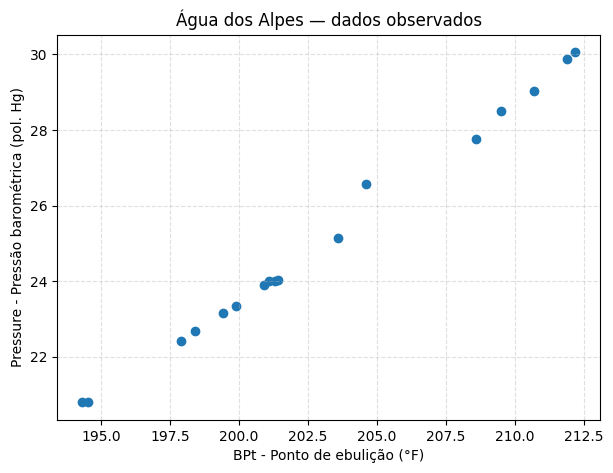

In [3]:
plt.scatter(df_alpes["BPt"], df_alpes["Pressure"], color="tab:blue")
plt.xlabel("BPt - Ponto de ebulição (°F)")
plt.ylabel("Pressure - Pressão barométrica (pol. Hg)")
plt.title("Água dos Alpes — dados observados")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

In [4]:
X_alpes = df_alpes[["BPt"]].values
y_alpes = df_alpes["Pressure"].values

modelo_alpes = LinearRegression()
modelo_alpes.fit(X_alpes, y_alpes)

coef_angular = modelo_alpes.coef_[0]
coef_linear = modelo_alpes.intercept_

print(f"Coeficiente angular (a): {coef_angular:.4f}")
print(f"Coeficiente linear  (b): {coef_linear:.4f}")
print(f"Reta ajustada: Pressure = {coef_angular:.4f} * BPt + ({coef_linear:.4f})")

Coeficiente angular (a): 0.5229
Coeficiente linear  (b): -81.0637
Reta ajustada: Pressure = 0.5229 * BPt + (-81.0637)


### Métricas de regressão

Como o exercício não pede divisão treino/teste para este caso, as métricas
abaixo são calculadas sobre o próprio conjunto de treino, para avaliar a
qualidade do ajuste da reta aos 17 pontos observados.

In [5]:
y_pred_alpes = modelo_alpes.predict(X_alpes)

r2_alpes = r2_score(y_alpes, y_pred_alpes)
mse_alpes = mean_squared_error(y_alpes, y_pred_alpes)
mae_alpes = mean_absolute_error(y_alpes, y_pred_alpes)

print(f"R²   = {r2_alpes:.4f}")
print(f"MSE  = {mse_alpes:.4f}")
print(f"MAE  = {mae_alpes:.4f}")

R²   = 0.9944
MSE  = 0.0478
MAE  = 0.1616


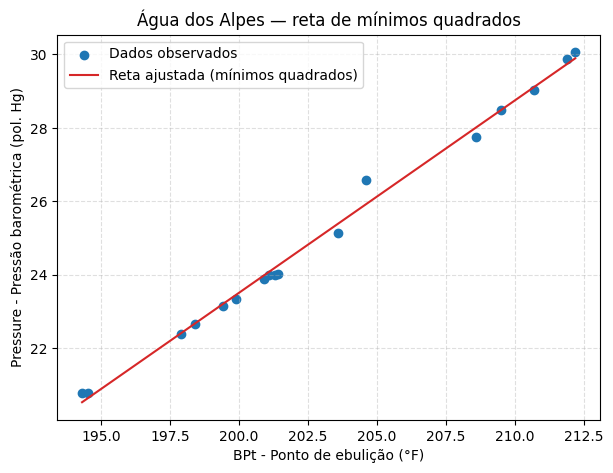

In [6]:
plt.scatter(df_alpes["BPt"], df_alpes["Pressure"], color="tab:blue", label="Dados observados")
ordem = np.argsort(X_alpes[:, 0])
plt.plot(X_alpes[ordem, 0], y_pred_alpes[ordem], color="tab:red", label="Reta ajustada (mínimos quadrados)")
plt.xlabel("BPt - Ponto de ebulição (°F)")
plt.ylabel("Pressure - Pressão barométrica (pol. Hg)")
plt.title("Água dos Alpes — reta de mínimos quadrados")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

### Previsões pedidas

Qual o valor de pressão para a temperatura de 200°F? E em 215°F?

In [7]:
for temperatura in [200, 215]:
    pressao_prevista = modelo_alpes.predict([[temperatura]])[0]
    print(f"BPt = {temperatura}°F  ->  Pressão prevista = {pressao_prevista:.4f} pol. Hg")

BPt = 200°F  ->  Pressão prevista = 23.5148 pol. Hg
BPt = 215°F  ->  Pressão prevista = 31.3581 pol. Hg


**Observação:** 215°F está fora do intervalo observado nos dados (194,3°F a
212,2°F) — é uma **extrapolação**. A previsão para 200°F é mais confiável por
estar dentro do intervalo observado (interpolação); a de 215°F deve ser vista
com mais cautela, já que o modelo assume que a relação linear continua
válida além dos dados observados.

---
## Parte 2 — Mínimos Quadrados: Livros e Aulas x Notas

Regressão linear **múltipla**: duas variáveis de entrada (`livros` e `aulas`)
e uma variável de saída (`notas`). O modelo ajusta um plano
$notas = a_1 \cdot livros + a_2 \cdot aulas + b$ que melhor aproxima as 40
observações.

In [8]:
df_notas = pd.read_csv("notas.csv")
df_notas.head(10)

,livros,aulas,notas
0,0,9,45
1,1,15,57
2,0,10,45
3,2,16,51
4,4,10,65
5,4,20,88
6,1,11,44
7,4,20,87
8,3,15,89
9,0,15,59


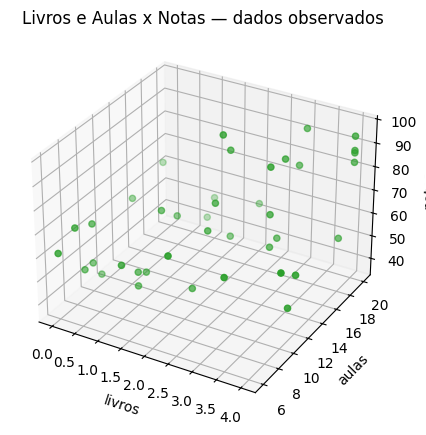

In [9]:
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.scatter(df_notas["livros"], df_notas["aulas"], df_notas["notas"], color="tab:green")
ax.set_xlabel("livros")
ax.set_ylabel("aulas")
ax.set_zlabel("notas")
ax.set_title("Livros e Aulas x Notas — dados observados")
plt.show()

In [10]:
X_notas = df_notas[["livros", "aulas"]].values
y_notas = df_notas["notas"].values

modelo_notas = LinearRegression()
modelo_notas.fit(X_notas, y_notas)

coef_livros, coef_aulas = modelo_notas.coef_
intercepto_notas = modelo_notas.intercept_

print(f"Coeficiente (livros): {coef_livros:.4f}")
print(f"Coeficiente (aulas):  {coef_aulas:.4f}")
print(f"Intercepto (b):       {intercepto_notas:.4f}")
print(f"Modelo: notas = {coef_livros:.4f}*livros + {coef_aulas:.4f}*aulas + ({intercepto_notas:.4f})")

Coeficiente (livros): 4.0369
Coeficiente (aulas):  1.2835
Intercepto (b):       37.3792
Modelo: notas = 4.0369*livros + 1.2835*aulas + (37.3792)


### Métricas de regressão

Assim como no problema anterior, o enunciado não pede divisão treino/teste
para este caso — as métricas abaixo avaliam o ajuste do modelo às 40
observações usadas no treino.

In [11]:
y_pred_notas = modelo_notas.predict(X_notas)

r2_notas = r2_score(y_notas, y_pred_notas)
mse_notas = mean_squared_error(y_notas, y_pred_notas)
mae_notas = mean_absolute_error(y_notas, y_pred_notas)

print(f"R²   = {r2_notas:.4f}")
print(f"MSE  = {mse_notas:.4f}")
print(f"MAE  = {mae_notas:.4f}")

R²   = 0.3287
MSE  = 182.6557
MAE  = 11.3714


**Observação:** o R² deste modelo é bem mais baixo que o do problema
anterior (Água dos Alpes). Isso é esperado: `livros` e `aulas` explicam
parte da variação nas notas, mas fatores não capturados nos dados (esforço
individual em provas, conhecimento prévio, etc.) também influenciam o
resultado — diferente do caso da água, onde a relação física entre pressão
e ponto de ebulição é quase perfeitamente linear.

### Previsões pedidas

Quais são as notas previstas dos alunos que leram e assistiram,
respectivamente: (2 livros, 11 aulas), (0, 5), (4, 20), (2, 10) e (4, 15)?

In [12]:
casos = [(2, 11), (0, 5), (4, 20), (2, 10), (4, 15)]

for livros, aulas in casos:
    nota_prevista = modelo_notas.predict([[livros, aulas]])[0]
    print(f"livros={livros:>2} | aulas={aulas:>2}  ->  Nota prevista = {nota_prevista:.2f}")

livros= 2 | aulas=11  ->  Nota prevista = 59.57
livros= 0 | aulas= 5  ->  Nota prevista = 43.80
livros= 4 | aulas=20  ->  Nota prevista = 79.20
livros= 2 | aulas=10  ->  Nota prevista = 58.29
livros= 4 | aulas=15  ->  Nota prevista = 72.78


---
## Parte 3 — Classificação: KNN no Iris Flower Dataset

Diferente dos dois problemas anteriores, este é um problema de
**classificação**: a partir de 4 medidas (comprimento/largura de sépala e
pétala), o modelo deve prever a qual das 3 espécies (`setosa`, `versicolor`,
`virginica`) uma flor pertence. Os dados são carregados diretamente do
`sklearn.datasets`, como sugerido no enunciado, e divididos em treino e
teste conforme pedido na entrega.

In [13]:
iris_X, iris_y = load_iris(return_X_y=True)
nomes_especies = load_iris().target_names

print("Formato de X:", iris_X.shape)
print("Formato de y:", iris_y.shape)
print("Classes:", nomes_especies)

Formato de X: (150, 4)
Formato de y: (150,)
Classes: ['setosa' 'versicolor' 'virginica']


In [14]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    iris_X, iris_y, test_size=0.3, random_state=42, stratify=iris_y
)

print(f"Exemplos de treino: {len(X_treino)}")
print(f"Exemplos de teste:  {len(X_teste)}")

Exemplos de treino: 105
Exemplos de teste:  45


In [15]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_treino, y_treino)

y_pred_knn = knn.predict(X_teste)

### Métricas de classificação

In [16]:
acuracia = accuracy_score(y_teste, y_pred_knn)
print(f"Acurácia no conjunto de teste: {acuracia:.4f} ({acuracia*100:.2f}%)")
print()
print("Relatório de classificação:")
print(classification_report(y_teste, y_pred_knn, target_names=nomes_especies))

Acurácia no conjunto de teste: 0.9778 (97.78%)

Relatório de classificação:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



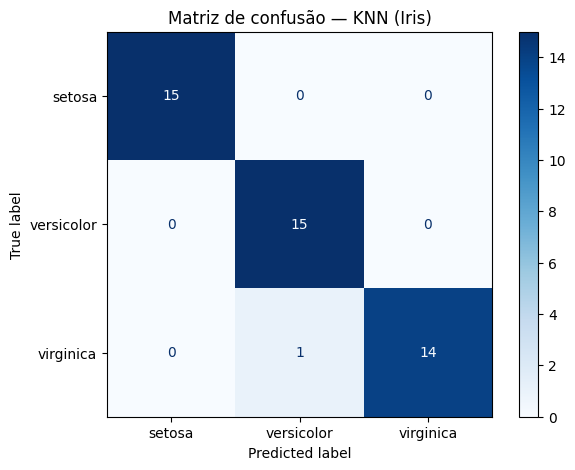

In [17]:
matriz_confusao = confusion_matrix(y_teste, y_pred_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=nomes_especies)
disp.plot(cmap="Blues")
plt.title("Matriz de confusão — KNN (Iris)")
plt.show()

### Escolha do número de vizinhos (k)

Como forma de discussão adicional, testamos a acurácia do KNN para diferentes
valores de $k$, para verificar se $k=5$ foi uma escolha razoável.

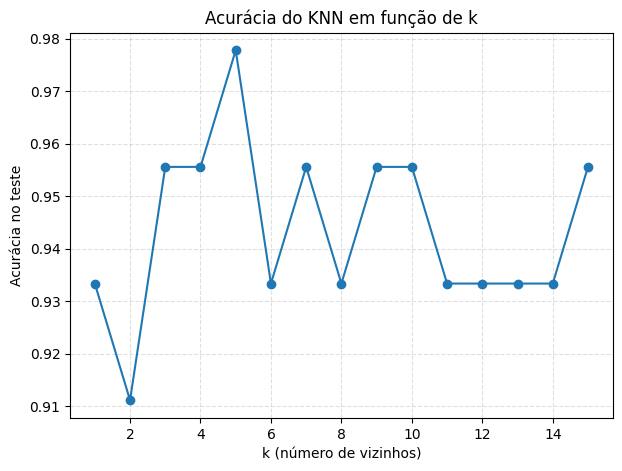

In [18]:
valores_k = range(1, 16)
acuracias_k = []

for k in valores_k:
    modelo_k = KNeighborsClassifier(n_neighbors=k)
    modelo_k.fit(X_treino, y_treino)
    acuracias_k.append(accuracy_score(y_teste, modelo_k.predict(X_teste)))

plt.plot(list(valores_k), acuracias_k, marker="o")
plt.xlabel("k (número de vizinhos)")
plt.ylabel("Acurácia no teste")
plt.title("Acurácia do KNN em função de k")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

---
## Conclusão

- **Água dos Alpes:** a regressão linear simples encontrou uma reta com bom
  ajuste aos 17 pontos observados (ver R² acima), permitindo prever a pressão
  barométrica a partir do ponto de ebulição da água. A previsão em 215°F é
  uma extrapolação e deve ser interpretada com mais cautela que a de 200°F.
- **Livros e Aulas x Notas:** a regressão linear múltipla mostrou como duas
  variáveis de entrada (número de livros lidos e de aulas assistidas)
  contribuem conjuntamente para prever a nota final dos alunos.
- **Iris Flower (KNN):** o classificador KNN obteve alta acurácia na
  separação das 3 espécies de Iris a partir das 4 medidas de sépala e pétala,
  confirmando que essas variáveis são bastante discriminativas entre as
  classes.